# Carterra: all 13 injections with one global Smax

Import **`carterra_rows.csv`**, inspect its metadata, and plot the measured
sensorgrams. This example uses a full-resolution selection committed with the repository;
it fits all 13 injections with pyKinGenie's existing one-site single-cycle fitter and one shared Smax. No data download is required.

The separate [five-injection notebook](15_carterra_csv_import.ipynb) retains the closer literature comparison. This notebook changes both the concentration selection and the capacity assumption from the published fit.

**Data origin:** [Duke TitrationAnalysis Carterra workbook](https://github.com/DukeCHSI/TitrationAnalysis/tree/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20Carterra). TitrationAnalysis tool, Kan Li and S Moses Dennison, Duke University. [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
This is a modified excerpt/conversion; the exact changes and pinned sources
are listed in [SOURCES.md](data/spr_exports/SOURCES.md).
The data and plotted sensorgrams retain their upstream license:
[full license notice](../test_files/spr_exports/TitrationAnalysis-LICENSE).

**Timing limitation:** the 1140 s cycle period is reconstructed from nominal protocol durations. An absolute injection log was not available. The fitted kinetic constants are conditional on this assumption; the notebook is not an exact reproduction of the published analysis.

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import display

# Works from the repository root, notebooks/ or docs/notebooks/.
repo_root = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (p / "src" / "pykingenie").is_dir())
sys.path[:0] = [str(repo_root / "src"), str(repo_root / "notebooks")]

from pykingenie import KineticsAnalyzer, read_info_sheet
from pykingenie.utils.plotting import plot_association_dissociation, plot_traces_all
from notebook_helpers import show_plotly_static

data_folder = repo_root / "notebooks" / "data" / "spr_exports"
fit_metadata = json.loads((data_folder / "fit_metadata.json").read_text())

## File layout and single-cycle import

The CSV retains **all 13 injections** for one physical sensor (Block 1/A1/ROI 1),
worksheet rows 2–14, in their original acquisition order. The five concentrations
on page 1 of the author fit report are injections **9–13** (worksheet rows 10–14):
**62.5, 125, 250, 500, 1000 nM**. This notebook fits **every injection**, from **0.244 to 1000 nM**, with one global Smax. The published report instead fits only the five highest concentrations with local Rmax.

Use `single_cycle=True, cycle_duration=1140` to combine the row-wise exports into
one sensor with **27 steps**: baseline, association, dissociation, association,
dissociation, ... . Each following pre-association baseline extends the preceding
dissociation because analyte is absent during that interval. Responses are not
shifted or interpolated during import, and source labels are retained in
`ligand_conc_df["Source_curve"]`.

**Clock assumption:** 1140 s is the nominal sum of the source sheet's baseline
120 s, association 300 s and fitted dissociation 720 s. This is an explicit
protocol-based reconstruction, not a recovered absolute injection log. Use the
actual cycle period when available. The source excerpts retain all finite points
in each row's 0–1140 s window; their later export tails are omitted and recorded
in the manifest. No response is smoothed or replaced.

## Import with the companion Data Info Sheet

The TitrationAnalysis sample sheet that accompanies the export supplies the
association window (`Bsl Start` + `Baseline`, then `Association`), the molar
concentrations and the analyte (`sample_id`). `read_info_sheet` shows how pyKinGenie
reads it.

Its included rows (A1, A5, A9) share the same timing and concentrations. The
cycle period, Baseline + Association + Dissociation = 1140 s, rebuilds the
single-cycle clock. Curves outside the sheet's *Incl. Conc.* start unselected
(`Select` column).

`pyKinetics.load` detects the file format (`carterra_csv`), reads the file with `CarterraExperiment.read_csv` and adds the experiment to the analyzer; the keyword options go to that reader.

In [2]:
data_file = data_folder / "carterra_rows.csv"
info_file = data_folder / "metadata" / "Example Data Info Sheet - Carterra.xlsx"

pyKinetics = KineticsAnalyzer()
experiment = pyKinetics.load(data_file, info=info_file, single_cycle=True)

display(pd.Series(experiment.exp_info["info_sheet"], name="Info sheet row"))
experiment.ligand_conc_df

Included                                                                           True
Block                                                                           1,2,3,4
Position                                                                             A1
Analyte                                                                         AE.A244
Ligand                                                                     CH31 10µg/ml
Baseline_start_s                                                                    0.0
Baseline_s                                                                        120.0
Association_s                                                                     300.0
Dissociation_s                                                                    720.0
Association_skip_s                                                                  0.0
Dissociation_skip_s                                                                 0.0
Concentrations_micromolar       

,Sensor,Analyte_location,Concentration_micromolar,SampleID,Replicate,Loading_location,Experiment,Select,Source_curve
0,single_cycle,1,0.000244,AE.A244,1,0,carterra_rows,False,[Ligand 1-AE.A244 Conc. 13] [NotFitted]
1,single_cycle,2,0.000488,AE.A244,1,0,carterra_rows,False,[Ligand 1-AE.A244 Conc. 12] [NotFitted]
2,single_cycle,3,0.000977,AE.A244,1,0,carterra_rows,False,[Ligand 1-AE.A244 Conc. 11] [NotFitted]
3,single_cycle,4,0.001950,AE.A244,1,0,carterra_rows,False,[Ligand 1-AE.A244 Conc. 10] [NotFitted]
4,single_cycle,5,0.003910,AE.A244,1,0,carterra_rows,False,[Ligand 1-AE.A244 Conc. 9] [NotFitted]
5,single_cycle,6,0.007810,AE.A244,1,0,carterra_rows,False,[Ligand 1-AE.A244 Conc. 8] [NotFitted]
6,single_cycle,7,0.015600,AE.A244,1,0,carterra_rows,False,[Ligand 1-AE.A244 Conc. 7] [NotFitted]
7,single_cycle,8,0.031300,AE.A244,1,0,carterra_rows,False,[Ligand 1-AE.A244 Conc. 6] [NotFitted]
8,single_cycle,9,0.062500,AE.A244,1,0,carterra_rows,True,[Ligand 1-AE.A244 Conc. 5] [NotFitted]
9,single_cycle,10,0.125000,AE.A244,1,0,carterra_rows,True,[Ligand 1-AE.A244 Conc. 4] [NotFitted]


All 13 rows become one sensor (`single_cycle`). The original row labels are kept in
`Source_curve`; `Analyte_location` numbers the injections in acquisition order.
Each later baseline belongs to the preceding dissociation, giving 13
association/dissociation pairs after one initial baseline.

In [3]:
experiment.df_steps

,#Step,Name,Type,Start,Column_location,Loading_location
0,1,Baseline,BASELINE,1.25,0,NaN
1,2,Association 1,ASSOC,120.00,1,0
2,3,Dissociation 1,DISASSOC,420.00,1,NaN
3,4,Association 2,ASSOC,1260.00,2,0
4,5,Dissociation 2,DISASSOC,1560.00,2,NaN
5,6,Association 3,ASSOC,2400.00,3,0
6,7,Dissociation 3,DISASSOC,2700.00,3,NaN
7,8,Association 4,ASSOC,3540.00,4,0
8,9,Dissociation 4,DISASSOC,3840.00,4,NaN
9,10,Association 5,ASSOC,4680.00,5,0


## Imported single-cycle sensorgram

All retained observations on the reconstructed protocol clock, before alignment.
The bound signal carries over from one injection to the next.

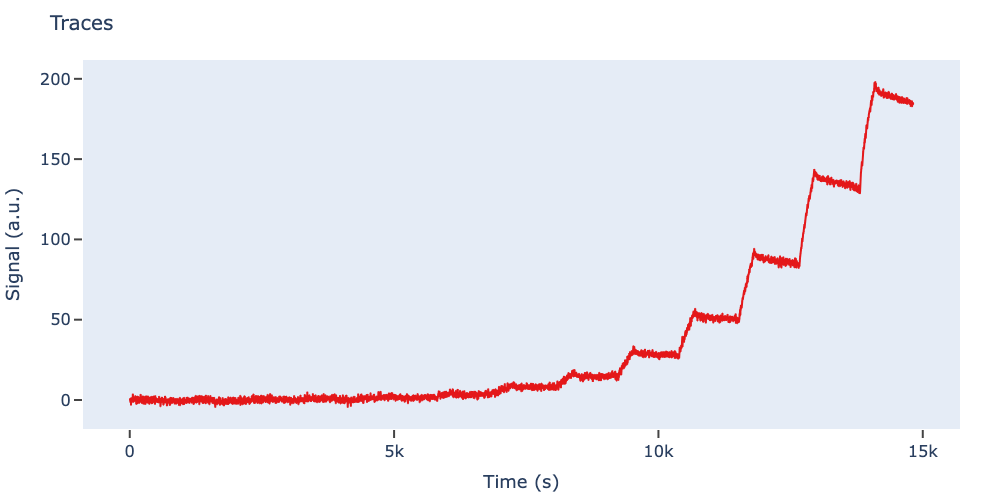

In [4]:
show_plotly_static(plot_traces_all(pyKinetics, pyKinetics.get_legends_table()),
                   width=1000, height=500, scale=1)

## One-site single-cycle model with global Smax

Use pyKinGenie's existing one-site association/dissociation fitter with
`shared_smax=True`: **one Kd, one koff and one Smax shared by all 13 injections**.
The source sample sheet specifies association 120–420 s, dissociation 420–1140 s,
no regeneration and no bulk shift.

`align_association` aligns only the first baseline because all subsequent
associations directly follow dissociations. The existing fitter starts the first
association at zero aligned response and carries the fitted bound signal forward
from each dissociation into the following association. No custom fitter or
per-injection reset is used.

The [author report](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20Carterra/Titration%20Analysis_Carterra_Report_Example.csv)
uses five injections and local Rmax. Its values are included below as context,
**not as an identical fitting setup**. Reference: [Li et al., TitrationAnalysis](https://pmc.ncbi.nlm.nih.gov/articles/PMC10667272/).

## Align and fit with `KineticsAnalyzer`

`align_association` subtracts the mean of the last 10 baseline points.
`generate_fittings` builds one fitter per sample, `submit_steady_state_fitting`
provides the starting values and `submit_kinetics_fitting` runs the one-site
association/dissociation model on every observation (`trim_time=0`).

All 13 injections are fitted with `shared_smax=True`, so the info sheet's five-injection selection is overridden.

In [5]:
experiment.align_association(npoints=10)

pyKinetics.merge_ligand_conc_df()
curves = pyKinetics.combined_ligand_conc_df
curves["Select"] = True
pyKinetics.generate_fittings(curves, trim_time=0)
pyKinetics.submit_steady_state_fitting()
pyKinetics.submit_kinetics_fitting(fitting_model="one_to_one", shared_smax=True)

pyKinetics.get_fitting_results()
pyKinetics.fit_params_kinetics_all

,Kd [µM],k_off [1/s],Smax,(Derived) k_on [1/µM/s],Name
0,0.022363,0.000086,224.183513,0.003837,AE.A244


## Leave-one-injection-out parameter errors

`calculate_leave_one_out_errors` refits the model 13 times, each time leaving one
injection out, and reports the mean ± standard deviation of Kd and koff over the
refits. This is the spread of deletion estimates, not a confidence interval.

**Single-cycle interpretation:** deleting an injection leaves a gap in the sequence.
The fitter estimates the starting response of the next retained association from
its observed signal (first 30 s) and then resumes carrying the bound state forward.
These results measure sensitivity to omitting an injection; they are not held-out
prediction errors.

In [6]:
pyKinetics.calculate_leave_one_out_errors()
pyKinetics.fittings[pyKinetics.fittings_names[0]].df_fit_loo

,Kd [µM],k_off [1/s]
0,2.36e-02 ± 2.62e-03,9.32e-05 ± 1.01e-05


## All 13 injections: single-cycle fit with global Smax

The package's `plot_association_dissociation` displays observations and the
fitted curves. Its plotting budget limits displayed
points only; the fit uses all observations allowed by `trim_time`.

**Check the published figure:** [Author fitted-sensorgram PDF](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20Carterra/Titration%20Analysis_Carterra_Sensorgram_Example.pdf).
Locate Block 1 / A1 / ROI 1, fitting #1; ligand CH31 10 µg/ml, analyte AE.A244. Only injections 9–13 appear on **page 1** of that report; its local-Rmax fit differs from the all-injection global-Smax fit below.

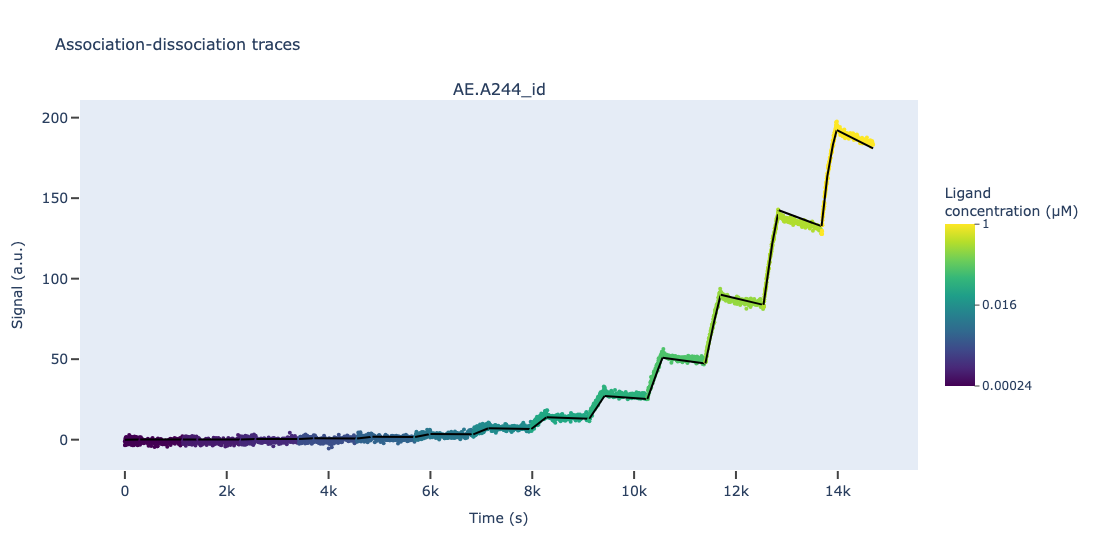

In [7]:
show_plotly_static(plot_association_dissociation(pyKinetics, split_by_smax_id=False),
                   width=1100, height=550, scale=1)

## Published values as context: different selection and Smax assumption

The single global Smax is shown in the library result table above. The published values use five injections and local Rmax, whereas this notebook uses all 13 and global Smax.

**Check the published numbers:** [Original parameter table (PDF)](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20Carterra/Titration%20Analysis_Carterra_Report_Example.pdf) or [machine-readable values (CSV)](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20Carterra/Titration%20Analysis_Carterra_Report_Example.csv).
Use Block 1 / A1 / ROI 1, fitting #1; ligand CH31 10 µg/ml, analyte AE.A244. These are the values in the Published column below.

In [8]:
fitter = pyKinetics.fittings[pyKinetics.fittings_names[0]]
reference = fit_metadata[experiment.name]["literature_reference"]["parameters_molar"]

comparison = pd.DataFrame(
    {"Published": [reference["kon"], reference["koff"], reference["Kd"] * 1e9],
     "pyKinGenie": [fitter.k_off / fitter.Kd * 1e6, fitter.k_off, fitter.Kd * 1e3]},
    index=["kon (M⁻¹ s⁻¹)", "koff (s⁻¹)", "Kd (nM)"],
)
comparison["Difference (%)"] = 100 * (comparison["pyKinGenie"] / comparison["Published"] - 1)
comparison.style.format("{:.4g}")

,Published,pyKinGenie,Difference (%)
kon (M⁻¹ s⁻¹),5161,3837,-25.66
koff (s⁻¹),7.373e-05,8.581e-05,16.37
Kd (nM),14.29,22.36,56.54


## Interpretation and limitations

The executed global-Smax fit gives approximately **Kd = 22.36 nM**,
**koff = 8.581 × 10⁻⁵ s⁻¹**, **kon = 3837 M⁻¹s⁻¹** and **Smax = 224.18 RU**.
Only three parameters are fitted. Leave-one-injection-out sensitivity is reported above.

One shared capacity leaves systematic response deviations in several injections.
The early injections have weak signals close to the noise. Treat these kinetic
constants as conditional on the one-site/global-capacity model and baseline and
timing assumptions; convergence alone does not establish their accuracy.

The nominal cycle period of 1140 s reconstructs the protocol clock; no absolute
injection log was available. Following baseline washes extend each preceding
dissociation. The published fit uses only the five highest concentrations and
local Rmax, so this is not an exact reproduction of its parameters.

See the [five-injection literature comparison](15_carterra_csv_import.ipynb),
[SPR_FITTING.md](SPR_FITTING.md), and [source notes](data/spr_exports/SOURCES.md).